In [27]:
import pandas as pd
from pathlib import Path
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv('DOHMH_Childcare_Center_Inspections_(Historical)_20261102.csv', thousands=",", low_memory=False)

In [8]:
df.head()

,Center Name,Legal Name,Building,Street,Borough,ZipCode,Phone,Permit Number,Permit Expiration,Status,...,Public Health Hazard Violation Rate,Average Public Health Hazard Violation Rate,Critical Violation Rate,Average Critical Violation Rate,Inspection Date,Regulation Summary,Violation Category,Health Code Sub Section,Violation Status,Inspection Summary Result
0,"JACKSON CHILDREN'S SERVICES, INC.","JACKSON CHILDREN'S SERVICES, INC.",88-23,31 AVENUE,QUEENS,11369.0,718-205-1919,105769.0,08/10/2024,Permitted,...,0.0,6.1285,50.0,18.9541,12/07/2022,At time of inspection floors/walls ceilings we...,GENERAL,47.41(j),OPEN,Initial Annual Inspection - Reinspection Not R...
1,"JACKSON CHILDREN'S SERVICES, INC.","JACKSON CHILDREN'S SERVICES, INC.",88-23,31 AVENUE,QUEENS,11369.0,718-205-1919,105769.0,08/10/2024,Permitted,...,0.0,6.1285,50.0,18.9541,12/07/2022,At time of inspection floors/walls ceilings we...,GENERAL,47.41(j),OPEN,Initial Annual Inspection - Reinspection Not R...
2,ATERET TORAH CENTER,BET YAAKOV ATERET TORAH,2166,CONEY ISLAND AVENUE,BROOKLYN,11223.0,718-375-7100,NaN,01/23/2115,Active,...,0.0,23.3017,50.0,35.2291,10/20/2022,School-based child care staff observed caring ...,GENERAL,43.11(b),OPEN,Initial Annual Inspection - Reinspection Required
3,PACKER SUMMER 2022,PACKER COLLEGIATE INSTITUTE,170,Joralemon Street,BROOKLYN,11201.0,718-250-0259,33693.0,09/15/2022,Expired-In Renewal,...,0.0,14.2558,0.0,21.8553,06/22/2022,There were no new violations observed at the t...,NaN,NaN,NaN,Initial Annual Inspection - Passed inspection ...
4,THE LEARNING EXPERIENCE,"RIVERDALE CHILDCARE EXPERIENCE, LLC",3210,Riverdale Avenue,BRONX,10463.0,718-708-5884,97738.0,09/28/2023,Permitted,...,NaN,NaN,NaN,NaN,11/05/2021,At time of inspection child care service unabl...,GENERAL,47.25(a)(1),CORRECTED,NaN


In [30]:
centers = df[[
    "Day Care ID", "Borough", "Child Care Type", "Maximum Capacity",
    "Total Educational Workers", "Violation Rate Percent",
]].drop_duplicates("Day Care ID")

centers.columns = ["id", "borough", "ctype", "capacity", "workers", "viol_rate"]

In [31]:
#Cleaning: remove centers that can't be compared fairly
centers = centers.dropna(subset=["viol_rate"])   # removing centers that have never been inspected
centers = centers[centers["ctype"] != "Camp"]    # camps reporting 0 workers
centers = centers[centers["workers"] > 0]        # 0 workers = missing data
print("Centers in model:", len(centers))

Centers in model: 2426


In [36]:
centers["staff_group"] = pd.cut(
    centers["workers"],
    bins=[0, 5, 10, 15, 20, 500],
    labels=["1-5", "6-10", "11-15", "16-20", "21+"],
)
print(centers.groupby("staff_group", observed=True)["viol_rate"].agg(["mean", "count"]).round(1))

             mean  count
staff_group             
1-5          25.4    680
6-10         24.8    823
11-15        24.5    426
16-20        25.6    248
21+          22.8    249


In [37]:
print(centers.groupby("borough")["viol_rate"].agg(["mean", "count"]).round(1))
print(centers.groupby("ctype")["viol_rate"].agg(["mean", "count"]).round(1))

               mean  count
borough                   
BRONX          45.3    280
BROOKLYN       23.1    919
MANHATTAN      17.3    564
QUEENS         26.4    539
STATEN ISLAND  18.6    124
                               mean  count
ctype                                     
Child Care - Infants/Toddlers  17.4    448
Child Care - Pre School        21.9   1604
School Based Child Care        45.9    374


In [32]:
#Regression

model = smf.ols(
    "viol_rate ~ workers + capacity + C(ctype) + C(borough)",
    data=centers,
).fit(cov_type="HC3")   # robust standard errors (rates are skewed)

In [33]:
print(model.summary().tables[1])
print("R-squared:", round(model.rsquared, 3))

                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              37.7841      2.320     16.289      0.000      33.238      42.331
C(ctype)[T.Child Care - Pre School]     3.0644      1.370      2.237      0.025       0.379       5.750
C(ctype)[T.School Based Child Care]    26.5966      2.444     10.884      0.000      21.807      31.386
C(borough)[T.BROOKLYN]                -20.8190      2.209     -9.424      0.000     -25.149     -16.489
C(borough)[T.MANHATTAN]               -26.2149      2.236    -11.722      0.000     -30.598     -21.832
C(borough)[T.QUEENS]                  -17.8087      2.335     -7.627      0.000     -22.385     -13.232
C(borough)[T.STATEN ISLAND]           -25.8743      3.323     -7.787      0.000     -32.386     -19.362
workers                                -0.0367      0.070     -0

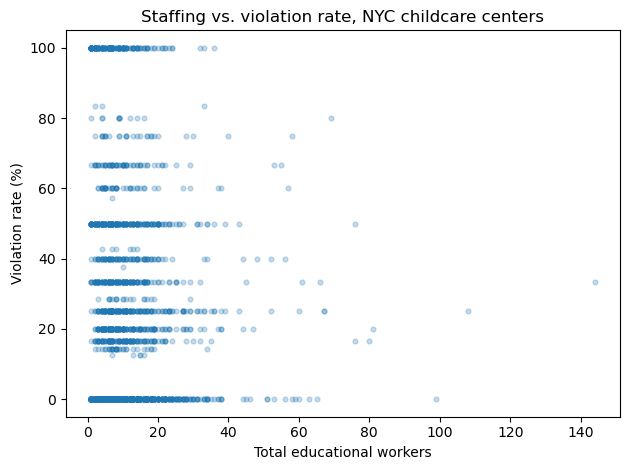

In [35]:
# Scatter plot
plt.scatter(centers["workers"], centers["viol_rate"], alpha=0.25, s=12)
plt.xlabel("Total educational workers")
plt.ylabel("Violation rate (%)")
plt.title("Staffing vs. violation rate, NYC childcare centers")
plt.tight_layout()
out_dir = Path("../output")
plt.savefig(out_dir / "workers_vs_violations.png", dpi=150)
plt.savefig("workers_vs_violations.png", dpi=150)